In [1]:
from rdkit import Chem
import sys
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
from rules import run_next_step, execute_step, prepare_molecule # pyright: ignore[reportMissingImports]
import helper # pyright: ignore[reportMissingImports]
from ml_helper import make_fingerprint # pyright: ignore[reportMissingImports]
import xgboost
import pickle
import random
import json
import numpy as np

In [2]:
clf = xgboost.XGBClassifier()
clf.load_model('models/v15/xg_model.json')

In [3]:
import os

# Load some existing arrows
num_dirs = len([name for name in os.listdir('training') if os.path.isdir(os.path.join('training', name))])
random_dir = random.randint(1, num_dirs + 1)
with open(f'training/{random_dir}/sm.pkl', 'rb') as f:
    sm = pickle.load(f)
num_arrows = len([fname for fname in os.listdir(f'training/{random_dir}') if fname.startswith('mol_')])
random_mol = random.randint(0, num_arrows)
with open(f'training/{random_dir}/mol_{random_mol}.pkl', 'rb') as f:
    next_mol = pickle.load(f)

with open(f'training/{random_dir}/data.json', 'r') as f:
    j_data = json.load(f)

mech = j_data['choices'][str(random_mol)]['mechanism']

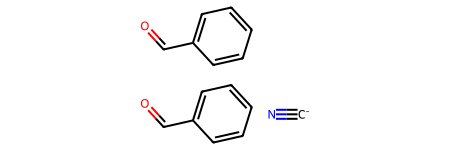

In [4]:
sm

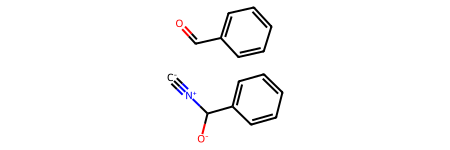

In [5]:
next_mol

In [6]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

In [7]:
mech

[1, 1, 3, None, 2]

In [8]:
is_next_step = True
next_step = [0,0,0,0,0]

In [84]:
def find_chain(next_mol, mech):
    bonds_to_highlight = []
    atoms_to_highlight = []
    prepare_molecule(next_mol)
    
    if mech[4] is not None:
        pot_source =next_mol.GetAtomWithIdx(mech[4])
        if pot_source.HasProp('source'):
            for a in next_mol.GetAtomWithIdx(mech[4]).GetNeighbors():
                if a.HasProp('sink'):
                    print(a.GetIdx(), a.GetSymbol(), a.GetProp('sink'))
                    atoms_to_highlight.append(a.GetIdx())
                for b in a.GetBonds():
                    if b.HasProp('sink'):
                        bonds_to_highlight.append(b.GetIdx())
                        print(b.GetIdx(), b.GetProp('sink'))
                
    if mech[3] is not None:
        pot_sink =next_mol.GetAtomWithIdx(mech[3])
        if pot_sink.HasProp('sink'):
            for a in next_mol.GetAtomWithIdx(mech[3]).GetNeighbors():
                if a.HasProp('source'):
                    print(a.GetIdx(), a.GetSymbol(), a.GetProp('source'))
                    atoms_to_highlight.append(a.GetIdx())
                for b in a.GetBonds():
                    if b.HasProp('source'):
                        bonds_to_highlight.append(b.GetIdx())
                        print(b.GetIdx(), b.GetProp('source'))


    for a in next_mol.GetAtoms():
        if a.GetIdx() not in atoms_to_highlight + [mech[3], mech[4]]:
            a.ClearProp('source')
            a.ClearProp('sink')
            if a.GetFormalCharge() == 0:
                a.SetNoImplicit(False)
    for b in next_mol.GetBonds():
        if b.GetIdx() not in bonds_to_highlight:
            b.ClearProp('source')
            b.ClearProp('sink')
            b.ClearProp('source_bond_atom')
            b.ClearProp('sink_bond_atom')
            b.ClearProp('source_other_atom')
    Chem.Draw.MolToImage(next_mol, size=(300, 300), highlightBonds=bonds_to_highlight, highlightAtoms=atoms_to_highlight)
    return (next_mol, bonds_to_highlight, atoms_to_highlight)

In [118]:
#import traceback

smiles = "C=CC=COC.C=CC(=O)OC"
mols, mechs, inp_mol = run_next_step(smiles, False, True)
filtered_mols = []
filtered_mechs = []
for i in range(len(mols)):
    fp = np.array(make_fingerprint(inp_mol, mechs[i]))
    pred = clf.predict(fp.reshape(1,-1))[0]
    if pred == 1:
        filtered_mols.append(mols[i])
        filtered_mechs.append(mechs[i])

all_follow_ons = []
for i, mol in enumerate(filtered_mols):
    next_mol, _, _ = find_chain(mol, filtered_mechs[i])
    try:
        connected_mols, mechanism, mol_inp = execute_step(next_mol)
    except Exception as e:
        #traceback.print_exc()
        print(e)
    for i, product in enumerate(connected_mols):
        fp = np.array(make_fingerprint(mol_inp, mechanism[i]))
        pred = clf.predict(fp.reshape(1,-1))[0]
        print(f'Product {i}, predicted: {pred}')
        all_follow_ons.append((product, next_mol, mechanism[i], pred))

filtered_follow_ons = []

for p, n_mol, mech, pred in all_follow_ons:
    if pred == 1:
        filtered_follow_ons.append((p, n_mol, mech))


6 pi star
7 sigma star
4 O lone pair
Product 0, predicted: 1
Product 1, predicted: 1
Product 2, predicted: 0
Product 3, predicted: 1
5 sigma star
8 sigma star
9 pi star
9 pi bond
Product 0, predicted: 1
Product 1, predicted: 0
Product 2, predicted: 0
Product 3, predicted: 1
Product 4, predicted: 1
Product 5, predicted: 0
Product 6, predicted: 0
Product 7, predicted: 0


In [119]:
all_follow_ons

[(<rdkit.Chem.rdchem.Mol at 0x7f82dff1d690>,
  [0, 4, 3, None, None],
  np.int64(1)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff02810>,
  [0, 10, 3, None, None],
  np.int64(1)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2ed50>,
  [1, 4, 8, None, 9],
  np.int64(0)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2d460>,
  [1, 10, 8, None, 9],
  np.int64(1)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2edc0>,
  [0, 9, 6, None, None],
  np.int64(1)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2da80>,
  [1, 9, 8, None, 10],
  np.int64(0)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2d770>,
  [1, 9, 7, None, 8],
  np.int64(0)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2d9a0>,
  [1, 9, 8, None, 7],
  np.int64(1)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2db60>,
  [1, 7, 6, 8, None],
  np.int64(1)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2e8f0>,
  [1, 8, 6, 7, None],
  np.int64(0)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2f1b0>,
  [3, 7, 8, 8, 10],
  np.int64(0)),
 (<rdkit.Chem.rdchem.Mol at 0x7f82dff2f060>,
  [10, None, 8, None, 10],
  np.

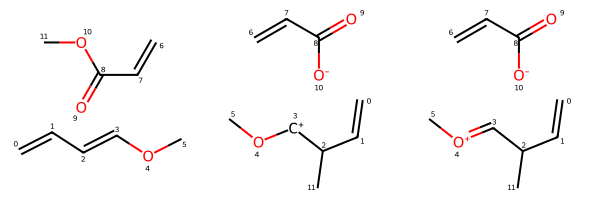

In [129]:
i = 0
Chem.Draw.MolsToGridImage([inp_mol, filtered_follow_ons[i][1], filtered_follow_ons[i][0]], molsPerRow=3)

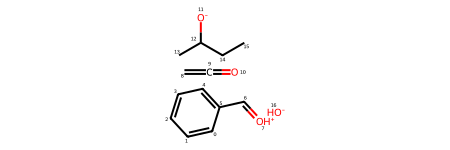

In [80]:
connected_mols[0]

In [53]:
for a in next_mol.GetAtoms():
    if a.HasProp('source'):
        print(a.GetIdx(), a.GetSymbol(), a.GetProp('source'))

0 I lone pair
